<a href="https://colab.research.google.com/github/DevPatel1023/UK-house-price-prediction/blob/main/Uk_house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Problem statement :

The uk's real estate or house market specifically is uncertain we can't
predict price easily which causes a critical problem of data fragmentation also if we try to conduct human
surveys for this , costs hundreds of pounds, and stalls mortgage approvals.
Sellers often overprice their homes based on emotional attachment, while estate agents
might inflate asking prices to win business, leading to properties sitting on the market for months

# Objective:

Understand which factors influence house prices, explore historical trends, and evaluate how
accurately a model can estimate prices for unseen examples.

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:

#unzip the dataset from google collab
!unzip "/content/drive/MyDrive/Colab Notebooks/Datasets/uk-house-price.zip"

Archive:  /content/drive/MyDrive/Colab Notebooks/Datasets/uk-house-price.zip
  inflating: UK_House_Price_Prediction_dataset_2015_to_2024.csv  


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# read data from dataset
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Datasets/uk-house-price.zip")


In [ ]:
# inspecting data-set using head method to find out how data-set look like
df.head(10)

,price,date,postcode,property_type,new_build,freehold,street,locality,town,district,county
0,735000,2017-08-07,LE17 5AP,D,N,F,CLAYBROOKE COURT,CLAYBROOKE PARVA,LUTTERWORTH,HARBOROUGH,LEICESTERSHIRE
1,160000,2023-02-03,SA11 4BD,T,N,F,GORED COTTAGES,MELINCOURT,NEATH,NEATH PORT TALBOT,NEATH PORT TALBOT
2,176500,2015-01-06,ME3 0DQ,S,N,F,GREEN LANE,ISLE OF GRAIN,ROCHESTER,MEDWAY,MEDWAY
3,625000,2021-10-13,RH20 3EU,D,N,F,LINFIELD COPSE,THAKEHAM,PULBOROUGH,HORSHAM,WEST SUSSEX
4,202000,2019-09-27,SN13 8EN,S,N,F,CLYDESDALE ROAD,BOX,CORSHAM,WILTSHIRE,WILTSHIRE
5,249950,2019-09-06,LS12 5FA,S,Y,F,FARNLEY PARK VIEW,FARNLEY,LEEDS,LEEDS,WEST YORKSHIRE
6,730000,2018-11-16,BA1 9AU,D,Y,F,BECKFORD DRIVE,LANSDOWN,BATH,BATH AND NORTH EAST SOMERSET,BATH AND NORTH EAST SOMERSET
7,185000,2023-12-18,NR10 5PB,S,N,F,NELSON WAY,HEVINGHAM,NORWICH,BROADLAND,NORFOLK
8,120000,2021-11-10,WS12 1DN,T,N,L,WELLINGTON MEWS,HEDNESFORD,CANNOCK,CANNOCK CHASE,STAFFORDSHIRE
9,124000,2017-12-08,HU12 8BZ,T,N,F,WESTLANDS CLOSE,HEDON,HULL,EAST RIDING OF YORKSHIRE,EAST RIDING OF YORKSHIRE


In [ ]:
# last rows of df
df.tail(10)

,price,date,postcode,property_type,new_build,freehold,street,locality,town,district,county
89990,198000,2023-03-31,LE19 2PU,T,N,F,DROVERS WAY,NARBOROUGH,LEICESTER,BLABY,LEICESTERSHIRE
89991,119950,2016-06-27,BB4 9RA,T,N,L,DEAN LANE,WATER,ROSSENDALE,ROSSENDALE,LANCASHIRE
89992,55000,2021-11-05,S66 1TT,F,N,L,PROGRESS DRIVE,BRAMLEY,ROTHERHAM,ROTHERHAM,SOUTH YORKSHIRE
89993,442500,2024-03-11,SG18 9DD,S,N,F,SHAKESPEARE DRIVE,UPPER CALDECOTE,BIGGLESWADE,CENTRAL BEDFORDSHIRE,CENTRAL BEDFORDSHIRE
89994,111000,2015-11-05,NG11 9HE,S,N,F,HAVENWOOD RISE,CLIFTON,NOTTINGHAM,CITY OF NOTTINGHAM,CITY OF NOTTINGHAM
89995,295000,2021-08-13,GL11 5UW,D,N,F,PEVELANDS,CAM,DURSLEY,STROUD,GLOUCESTERSHIRE
89996,325000,2021-12-07,WS3 3UJ,D,N,F,GLENEAGLES ROAD,BLOXWICH,WALSALL,WALSALL,WEST MIDLANDS
89997,167000,2015-11-06,BD17 5LR,S,N,F,CORNWALL CRESCENT,BAILDON,SHIPLEY,BRADFORD,WEST YORKSHIRE
89998,80000,2023-09-26,DN4 7RZ,F,N,L,STOOPS LANE,BESSACARR,DONCASTER,DONCASTER,SOUTH YORKSHIRE
89999,1912500,2019-02-08,NE11 0TU,O,N,L,PRINCESWAY,TEAM VALLEY TRADING ESTATE,GATESHEAD,GATESHEAD,TYNE AND WEAR


In [ ]:
# shape of data
df.shape

(90000, 11)

In [ ]:
# info about dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   price          90000 non-null  int64 
 1   date           90000 non-null  object
 2   postcode       90000 non-null  object
 3   property_type  90000 non-null  object
 4   new_build      90000 non-null  object
 5   freehold       90000 non-null  object
 6   street         90000 non-null  object
 7   locality       90000 non-null  object
 8   town           90000 non-null  object
 9   district       90000 non-null  object
 10  county         90000 non-null  object
dtypes: int64(1), object(10)
memory usage: 7.6+ MB


In [ ]:
# cols and data-type of cols
df.columns

#df.dtypes

Index(['price', 'date', 'postcode', 'property_type', 'new_build', 'freehold',
       'street', 'locality', 'town', 'district', 'county'],
      dtype='object')

In [ ]:
#description about data-set
df.describe()

,price
count,9.000000e+04
mean,3.238753e+05
std,1.282104e+06
min,1.000000e+02
25%,1.600000e+05
50%,2.449950e+05
75%,3.651588e+05
max,3.000000e+08


In [ ]:
from datetime import date
# date type
print(type(df['date'].iloc[0]))

# converting date to datetime
df['date'] = pd.to_datetime(df['date'])

# fetch year from date
df['year'] = df.date.dt.year

# fetch month from date
df['month'] = df.date.dt.month

<class 'str'>


In [ ]:
# dataset
df

,price,date,postcode,property_type,new_build,freehold,street,locality,town,district,county,year,month
0,735000,2017-08-07,LE17 5AP,D,N,F,CLAYBROOKE COURT,CLAYBROOKE PARVA,LUTTERWORTH,HARBOROUGH,LEICESTERSHIRE,2017,8
1,160000,2023-02-03,SA11 4BD,T,N,F,GORED COTTAGES,MELINCOURT,NEATH,NEATH PORT TALBOT,NEATH PORT TALBOT,2023,2
2,176500,2015-01-06,ME3 0DQ,S,N,F,GREEN LANE,ISLE OF GRAIN,ROCHESTER,MEDWAY,MEDWAY,2015,1
3,625000,2021-10-13,RH20 3EU,D,N,F,LINFIELD COPSE,THAKEHAM,PULBOROUGH,HORSHAM,WEST SUSSEX,2021,10
4,202000,2019-09-27,SN13 8EN,S,N,F,CLYDESDALE ROAD,BOX,CORSHAM,WILTSHIRE,WILTSHIRE,2019,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
89995,295000,2021-08-13,GL11 5UW,D,N,F,PEVELANDS,CAM,DURSLEY,STROUD,GLOUCESTERSHIRE,2021,8
89996,325000,2021-12-07,WS3 3UJ,D,N,F,GLENEAGLES ROAD,BLOXWICH,WALSALL,WALSALL,WEST MIDLANDS,2021,12
89997,167000,2015-11-06,BD17 5LR,S,N,F,CORNWALL CRESCENT,BAILDON,SHIPLEY,BRADFORD,WEST YORKSHIRE,2015,11
89998,80000,2023-09-26,DN4 7RZ,F,N,L,STOOPS LANE,BESSACARR,DONCASTER,DONCASTER,SOUTH YORKSHIRE,2023,9


In [ ]:
# find out duplicated values in dataset
print(df.duplicated())

# find out price has negative or zero values
df.loc[df['price'] <= 0]

# min and max price in dataset
print("min price:",df.price.min())
print("max price:",df.price.max())

0        False
1        False
2        False
3        False
4        False
         ...  
89995    False
89996    False
89997    False
89998    False
89999    False
Length: 90000, dtype: bool
min price: 100
max price: 300000000


# Visualization

## 1. Price Histogram

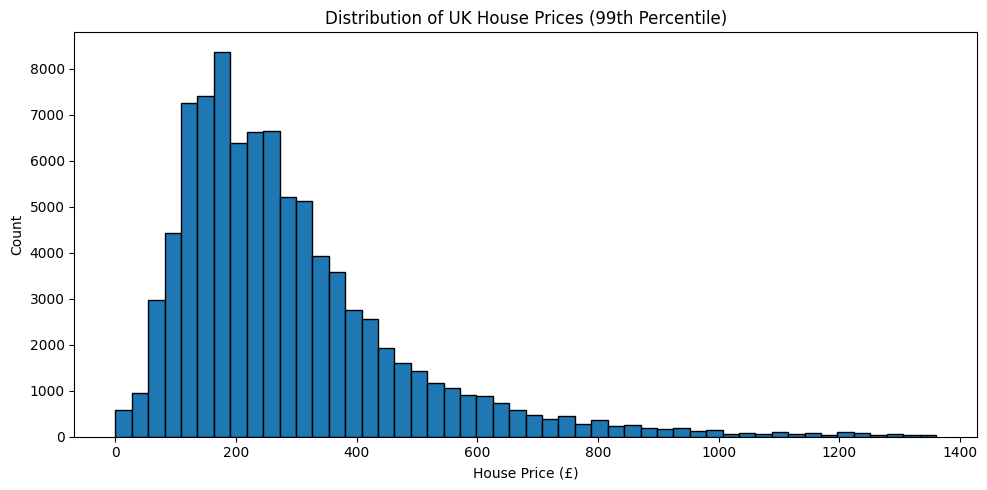

In [ ]:
from matplotlib import markers
# Histogram (count, price)

house_price = df['price'] / 1000

# Calculate the 99th percentile
upper_limit = house_price.quantile(0.99)


# Plot prices up to the 99th percentile
plt.figure(figsize=(10, 5))
plt.hist(
    house_price[house_price <= upper_limit],
    bins=50,
    edgecolor='black'
)

plt.xlabel('House Price (£)')
plt.ylabel('Count')
plt.title('Distribution of UK House Prices (99th Percentile)')
plt.ticklabel_format(axis='x', style='plain')
plt.tight_layout()
plt.show()


## 2. Highest vs Lowest Price Location-wise

Top 15


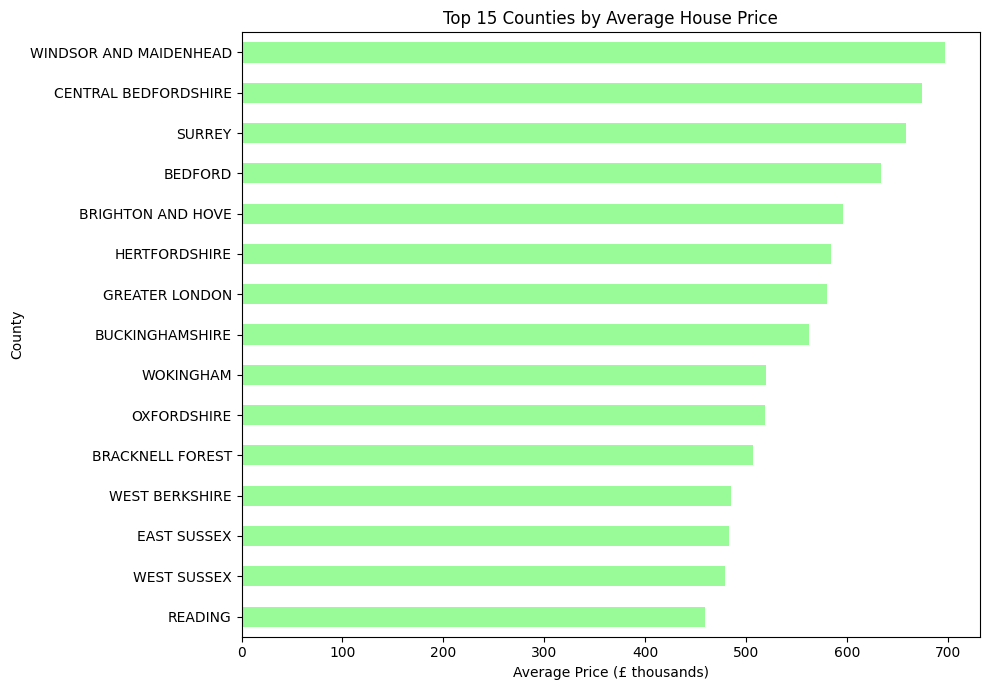

Bottom 15 


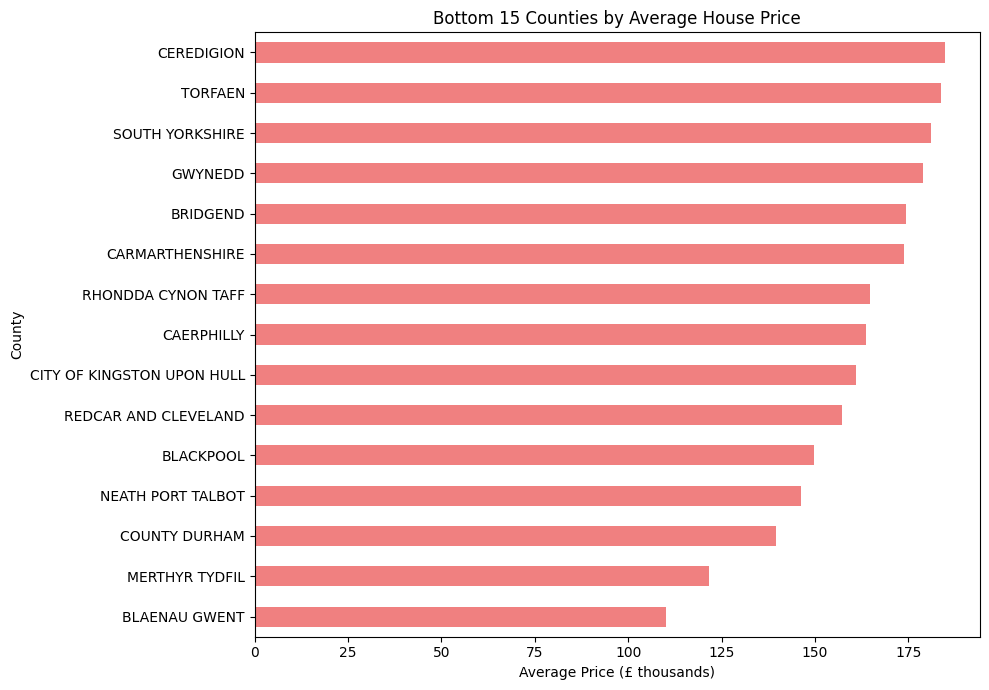

In [ ]:
# bar chart (price, country)
avg_price = df.groupby("county")["price"].mean()

top_15 = (avg_price.nlargest(15) / 1000).sort_values()

top_15.plot(kind="barh", figsize=(10, 7), color= 'palegreen')

print("Top 15")

# labels
plt.xlabel("Average Price (£ thousands)")
plt.ylabel("County")
plt.title("Top 15 Counties by Average House Price")
plt.tight_layout()
plt.show()

bottom_15 = (avg_price.nsmallest(15) / 1000).sort_values()

bottom_15.plot(kind="barh", figsize=(10, 7), color= 'lightcoral')

print("Bottom 15 ")
plt.xlabel("Average Price (£ thousands)")
plt.ylabel("County")
plt.title("Bottom 15 Counties by Average House Price")
plt.tight_layout()
plt.show()

## 3. Property-Type and Price

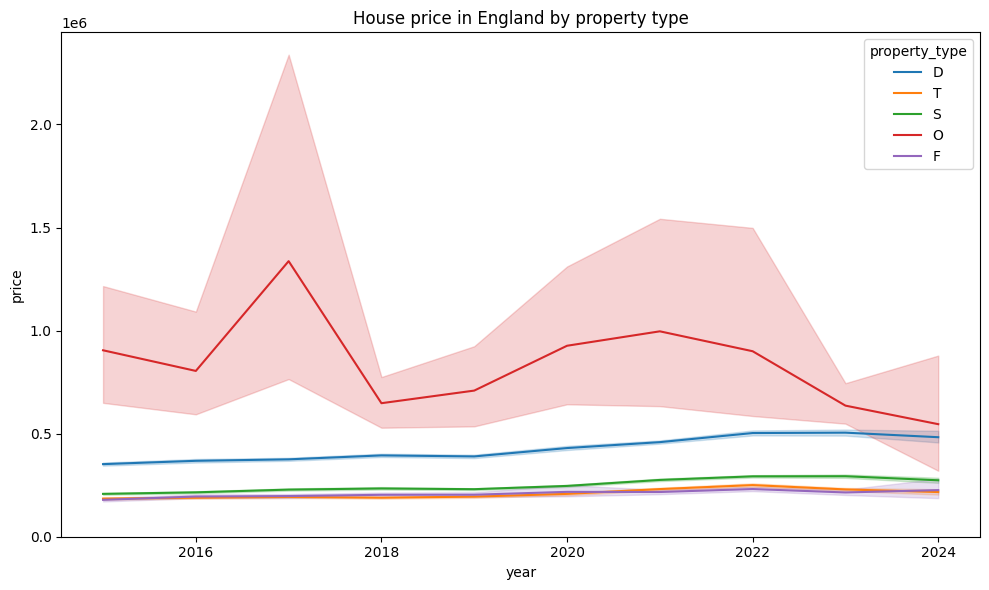

In [ ]:
# property type over price
plt.figure(figsize= (10, 6))

sns.lineplot(data = df, x= 'year', y= 'price', hue='property_type')

# labels
plt.title('House price in England by property type')
plt.xlabel('year')
plt.ylabel('price')
plt.tight_layout()
plt.ylim(0)

# show plot
plt.show()

## 4. Price trends over time — Line chart

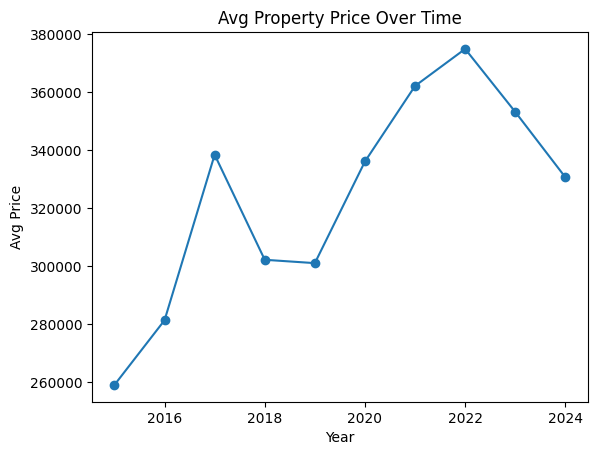

In [ ]:
df['date'] = pd.to_datetime(df['date'])

yearly = df.groupby(
    df['year']
)['price'].mean()

yearly.plot(kind='line', marker='o')
plt.title('Avg Property Price Over Time')
plt.xlabel('Year')
plt.ylabel('Avg Price')
plt.show()

## 5. New Building Prices

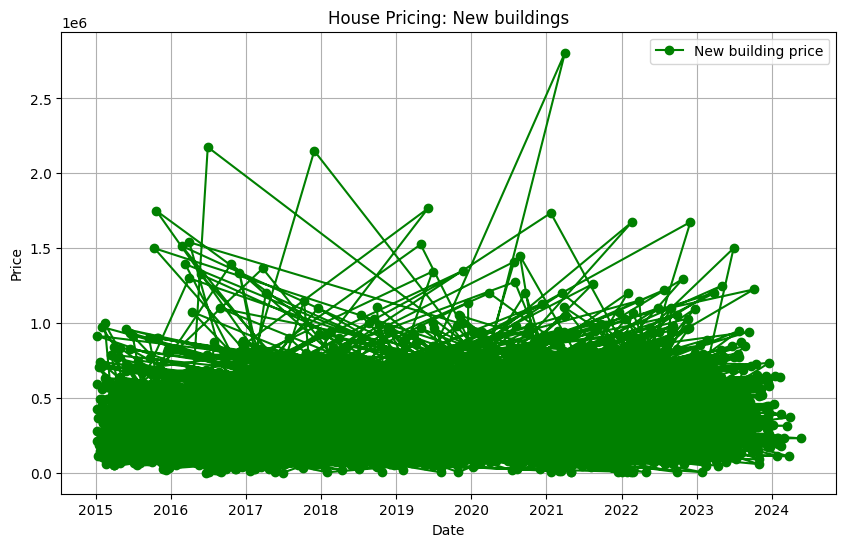

In [ ]:
new_building = df[df['new_build'] == 'Y']

# plot graph
plt.figure(figsize = (10, 6))

# new buildings
plt.plot(new_building['date'], new_building['price'], marker = 'o' , color = 'green', label= 'New building price')

# Graphs Labels
plt.title('House Pricing: New buildings')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()

# Grid view
plt.grid(True)

# show plot
plt.show()

## 6. Old Building Price

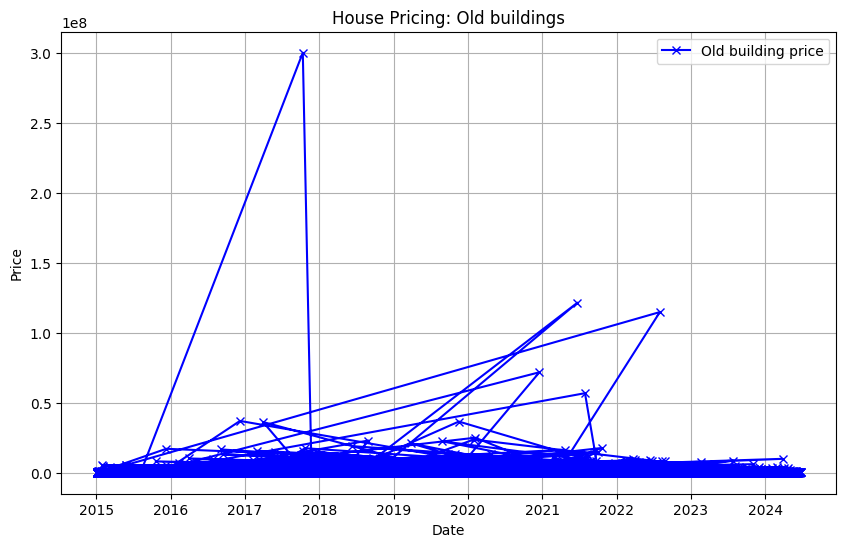

In [ ]:
old_building = df[df['new_build'] == 'N']

# plot graph
plt.figure(figsize = (10, 6))

# new buildings
plt.plot(old_building['date'], old_building['price'], marker = 'x' , color = 'blue', label= 'Old building price')

# Graphs Labels
plt.title('House Pricing: Old buildings')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()

# Grid view
plt.grid(True)

# show plot
plt.show()

# Data Handle

## New Building : if new building then encode label as Y = 1 and if old building then encode label it as Y = 0

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Initializa the label
le = LabelEncoder()

# categorical Y=YES=1,N=NO=0 columns to encode
categorical_col = [ 'new_build']

# Encode categorial column
for col in categorical_col :
  df[col] = le.fit_transform(df[col])

## Freehold : Indicator that property has sold on freehold or leasehold

### Freehold : f = 0 , Leasehold : l = 1



In [ ]:
# mapping dictonary
mapping = {
    'F' : 0 ,
    'L' : 1
}

df['freehold'] = df['freehold'].map(mapping)


## Unique country-wise analysis

In [ ]:
df['county'].unique()

array(['LEICESTERSHIRE', 'NEATH PORT TALBOT', 'MEDWAY', 'WEST SUSSEX',
       'WILTSHIRE', 'WEST YORKSHIRE', 'BATH AND NORTH EAST SOMERSET',
       'NORFOLK', 'STAFFORDSHIRE', 'EAST RIDING OF YORKSHIRE',
       'NORTH NORTHAMPTONSHIRE', 'COUNTY DURHAM', 'HEREFORDSHIRE', 'KENT',
       'SOUTHAMPTON', 'ESSEX', 'HAMPSHIRE', 'CITY OF DERBY',
       'LINCOLNSHIRE', 'OXFORDSHIRE', 'SUFFOLK', 'BUCKINGHAMSHIRE',
       'NORTH YORKSHIRE', 'LANCASHIRE', 'CORNWALL', 'SURREY',
       'SOUTH YORKSHIRE', 'BEDFORD', 'DERBYSHIRE', 'CONWY',
       'WEST MIDLANDS', 'THE VALE OF GLAMORGAN', 'SOUTH GLOUCESTERSHIRE',
       'CITY OF KINGSTON UPON HULL', 'WARWICKSHIRE', 'NORTHUMBERLAND',
       'CAMBRIDGESHIRE', 'GREATER MANCHESTER', 'SWINDON',
       'GREATER LONDON', 'MONMOUTHSHIRE', 'MERSEYSIDE', 'TORFAEN',
       'NOTTINGHAMSHIRE', 'READING', 'GLOUCESTERSHIRE',
       'STOCKTON-ON-TEES', 'DEVON', 'THURROCK', 'SOMERSET', 'WREXHAM',
       'SWANSEA', 'WEST NORTHAMPTONSHIRE', 'NORTHAMPTONSHIRE',
       'CA

## Country-wise house price values

In [ ]:
countries = df[['county','price']].groupby(['county'])
sum_prices = countries.sum()
df_price = sum_prices['price'].sort_values()
print(df_price[-5:])

county
ESSEX                  966761329
GREATER LONDON         997904268
HAMPSHIRE             1200657481
KENT                  1239284181
GREATER MANCHESTER    1252243924
Name: price, dtype: int64


In [ ]:
greater_london = df.loc[df['county'] == 'GREATER LONDON']
print(f'{greater_london.shape[0]} residents')

1718 residents


In [ ]:
greater_london['town'].unique()

array(['ROMFORD', 'HAYES', 'LONDON', 'BROMLEY', 'CROYDON', 'WESTERHAM',
       'ORPINGTON', 'SUTTON', 'BARNET', 'HAMPTON', 'ILFORD', 'UXBRIDGE',
       'HORNCHURCH', 'KINGSTON UPON THAMES', 'HOUNSLOW', 'RUISLIP',
       'HARROW', 'GREENFORD', 'SOUTH CROYDON', 'SIDCUP', 'WEST DRAYTON',
       'ERITH', 'PINNER', 'DARTFORD', 'TWICKENHAM', 'FELTHAM',
       'WALLINGTON', 'ISLEWORTH', 'SEVENOAKS', 'COULSDON', 'RICHMOND',
       'MITCHAM', 'CHIGWELL', 'SURBITON', 'DAGENHAM'], dtype=object)

In [ ]:
greater_london.groupby('town')['price'].mean()

,price
town,
BARNET,6.710211e+05
BROMLEY,5.014375e+05
CHIGWELL,3.455000e+05
COULSDON,2.250000e+05
CROYDON,3.387400e+05
DAGENHAM,3.670000e+05
DARTFORD,3.260434e+05
ERITH,2.725000e+05
FELTHAM,3.707273e+05


In [ ]:
town_groups = df[['town', 'price']].groupby('town')
town_prices = town_groups['price'].mean()
town_count = town_groups['price'].count()

towns = pd.DataFrame()
towns['mean_price'] = town_prices
towns['count'] = town_count

towns.sort_values('count',ascending=False)
towns.iloc[:3]

,mean_price,count
town,,
ABBOTS LANGLEY,865000.000000,1
ABERDARE,124291.261538,65
ABERGAVENNY,263498.396226,53


In [ ]:
london_residents = greater_london.loc[greater_london['town'].str.startswith('L')]

In [ ]:
london_residents['town'].unique() # finding unique towns

array(['LONDON'], dtype=object)

In [ ]:
london_residents = london_residents.loc[london_residents['town'] == 'LONDON']

In [ ]:
london_residents.shape[0] # no of rows

941

In [ ]:
london_residents['price'].mean()

np.float64(651653.2412327311)

### Property-wise

In [ ]:
df['property_type'].unique()

array(['D', 'T', 'S', 'O', 'F'], dtype=object)

In [ ]:
property_types = df.groupby('property_type')['price']

In [ ]:
property_wise_prices = df.groupby('property_type')['price'].mean()
property_wise_prices.sort_values()
property_wise_count = property_types.count()

property_wise_df = pd.DataFrame()
property_wise_df['mean_price'] = property_wise_prices
property_wise_df['count'] = property_wise_count

property_wise_df.sort_values('count',ascending=False)

,mean_price,count
property_type,,
D,419097.079119,30435
S,247828.935870,26228
T,207885.738400,21380
F,206463.751321,7568
O,885483.636591,4389


In [ ]:
df

,price,date,postcode,property_type,new_build,freehold,street,locality,town,district,county,year,month
0,735000,2017-08-07,LE17 5AP,D,0,0,CLAYBROOKE COURT,CLAYBROOKE PARVA,LUTTERWORTH,HARBOROUGH,LEICESTERSHIRE,2017,8
1,160000,2023-02-03,SA11 4BD,T,0,0,GORED COTTAGES,MELINCOURT,NEATH,NEATH PORT TALBOT,NEATH PORT TALBOT,2023,2
2,176500,2015-01-06,ME3 0DQ,S,0,0,GREEN LANE,ISLE OF GRAIN,ROCHESTER,MEDWAY,MEDWAY,2015,1
3,625000,2021-10-13,RH20 3EU,D,0,0,LINFIELD COPSE,THAKEHAM,PULBOROUGH,HORSHAM,WEST SUSSEX,2021,10
4,202000,2019-09-27,SN13 8EN,S,0,0,CLYDESDALE ROAD,BOX,CORSHAM,WILTSHIRE,WILTSHIRE,2019,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
89995,295000,2021-08-13,GL11 5UW,D,0,0,PEVELANDS,CAM,DURSLEY,STROUD,GLOUCESTERSHIRE,2021,8
89996,325000,2021-12-07,WS3 3UJ,D,0,0,GLENEAGLES ROAD,BLOXWICH,WALSALL,WALSALL,WEST MIDLANDS,2021,12
89997,167000,2015-11-06,BD17 5LR,S,0,0,CORNWALL CRESCENT,BAILDON,SHIPLEY,BRADFORD,WEST YORKSHIRE,2015,11
89998,80000,2023-09-26,DN4 7RZ,F,0,1,STOOPS LANE,BESSACARR,DONCASTER,DONCASTER,SOUTH YORKSHIRE,2023,9


## House Prices : Overall trends

### This section contains visualization that aims to analyse house prices between 2015 and 2019.

In [ ]:
df1 = df.copy()

In [ ]:
# Fetch house prices between 2015 and 2019
df1 = df1[(df1['year'] >= 2015) & (df1['year'] <= 2019)]
df1 = df1.reset_index(drop = True)
df1.head()

,price,date,postcode,property_type,new_build,freehold,street,locality,town,district,county,year,month
0,735000,2017-08-07,LE17 5AP,D,0,0,CLAYBROOKE COURT,CLAYBROOKE PARVA,LUTTERWORTH,HARBOROUGH,LEICESTERSHIRE,2017,8
1,176500,2015-01-06,ME3 0DQ,S,0,0,GREEN LANE,ISLE OF GRAIN,ROCHESTER,MEDWAY,MEDWAY,2015,1
2,202000,2019-09-27,SN13 8EN,S,0,0,CLYDESDALE ROAD,BOX,CORSHAM,WILTSHIRE,WILTSHIRE,2019,9
3,249950,2019-09-06,LS12 5FA,S,1,0,FARNLEY PARK VIEW,FARNLEY,LEEDS,LEEDS,WEST YORKSHIRE,2019,9
4,730000,2018-11-16,BA1 9AU,D,1,0,BECKFORD DRIVE,LANSDOWN,BATH,BATH AND NORTH EAST SOMERSET,BATH AND NORTH EAST SOMERSET,2018,11


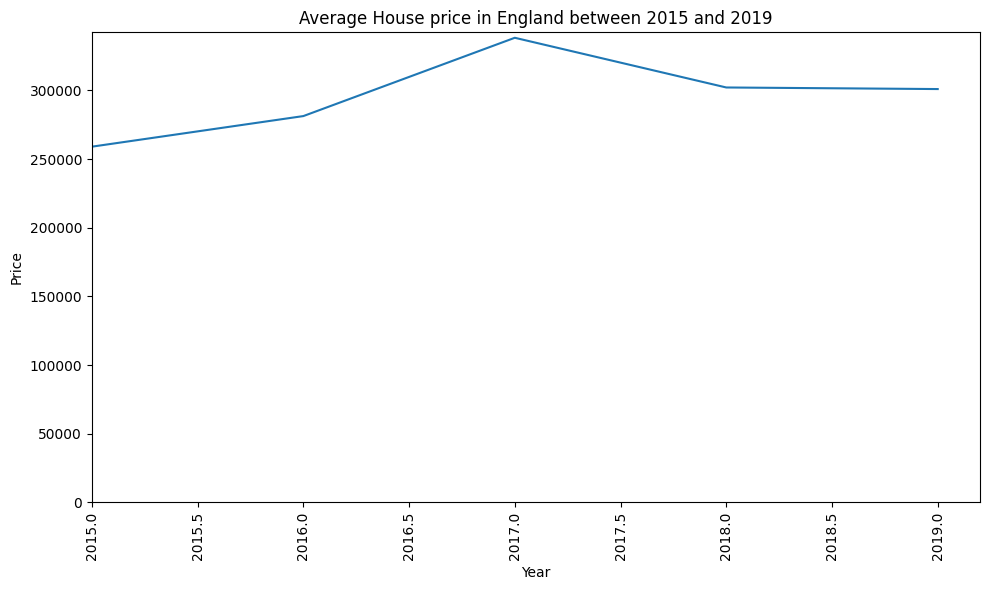

In [ ]:
# Group the data by year and find the average price for the year

df1 = df1.groupby('year')['price'].mean().reset_index()

# visualiza this df1 using line graph
plt.figure(figsize= (10,6))
sns.lineplot(df1,x= 'year', y= 'price')
plt.title('Average House price in England between 2015 and 2019')
plt.xlabel('Year')
plt.ylabel('Price')
plt.xticks(rotation=90)
plt.xlim(2015)
plt.ylim(0)
plt.tight_layout()
plt.show()

## remove unnecessary columns

In [ ]:
df.drop('date', axis = 1, inplace = True)

In [ ]:
df.drop('postcode',axis = 1 ,inplace = True)

In [ ]:
df.drop('district',axis = 1 ,inplace = True)

## Model training